# ۰۲ — سامانه هشدار زودهنگام: از داده خام تا فهرست پیگیری روزانه

**مسئله:** در لحظه تأیید هر سفارش، پیش‌بینی کنم کدام سفارش‌ها به نظر منفی (امتیاز ۱ یا ۲) می‌رسند، تا تیم پشتیبانی با ظرفیت **۱۰٪ سفارش‌ها** فقط سراغ پرخطرترین‌ها برود.

**معماری:** از قطعه‌های سه مرحله قبل ساخته شده است:

`[Olist CSV] + [API تعطیلات]` → package مرحله ۱ (قرارداد، قرنطینه، manifest) → PostgreSQL مرحله ۲ → ویژگی‌ها در پایگاه داده (View + Procedure + جدول snapshot) → لایه مدل با انضباط مرحله ۳ → فهرست ۱۰٪ روزانه

**یک فرمان:** `data-factory early-warning`. در سلول بعد همان فرمان را از داخل نوت‌بوک اجرا می‌کنم (همه مرحله‌ها، با زمان هر مرحله).

**بودجه زمانی:** کل چالش ۸ تا ۱۰ روز کاری. سقف اجرای سامانه ۴۵ دقیقه است و زمان واقعی در خروجی سلول بعد آمده.

In [1]:
import json, shutil, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from data_factory import ews_pipeline, ews_model as em
from data_factory.config import load_config
from data_factory.ews_audit import AUDIT, model_features
from data_factory.ews_predict import predict_folder
from data_factory.exceptions import SourceSchemaChangedError

config = load_config("factory.toml")
E, OUT = config.ews, config.ews.output_dir
SEED = E.seed
np.random.seed(SEED)
pd.set_option("display.width", 170, "display.max_columns", 25, "display.max_colwidth", 80,
              "display.float_format", "{:.4f}".format)
print("seed", SEED, "| cut-off", E.cutoff.date(), "| evaluation end", E.evaluation_end.date(), "| capacity", E.capacity)

seed 42 | cut-off 2018-04-01 | evaluation end 2018-09-01 | capacity 0.1


## ۱. اجرای کل زنجیره با یک فرمان، و زمان هر مرحله

In [2]:
timings = ews_pipeline.run(config)          # = data-factory early-warning
stage_table = pd.DataFrame({"seconds": timings["stages"]})
stage_table["minutes"] = stage_table.seconds / 60
print(f"total: {timings['total_seconds'] / 60:.1f} minutes (budget 45)")
stage_table

total: 2.7 minutes (budget 45)


,seconds,minutes
olist,122.1000,2.0350
holidays,0.3000,0.0050
features,13.2000,0.2200
model,22.0000,0.3667
followup,2.3000,0.0383


زمان هر مرحله جدا ثبت می‌شود (`data/curated/ews/timings.json`). بیشترین زمان مال بارگذاری Olist است: نه فایل، ۱.۵ میلیون رکورد، اعتبارسنجی، قرنطینه و `COPY` در یک تراکنش. کل زنجیره خیلی زیر بودجه ۴۵ دقیقه است.

## ۲. ویژگی‌ها، ساخته‌شده در پایگاه داده

ویژگی‌ها در `sql/ews/20_features.sql` ساخته می‌شوند:
- view `order_features_live` همه محاسبه‌ها را انجام می‌دهد.
- procedure `refresh_features()` خروجی view را در جدول snapshot `order_features` می‌ریزد.
- مدل فقط همین جدول را می‌خواند.

**کوئری تولید ویژگی** (`SELECT * FROM order_features`) را ۳ بار برای گرم شدن و ۲۰ بار با `EXPLAIN ANALYZE` اجرا کردم. پلن کامل در `data/curated/ews/feature_query_plan.json` ذخیره شده است.

In [3]:
query = timings["results"]["features"]["feature_query"]
plan = json.loads((OUT / "feature_query_plan.json").read_text())
print(json.dumps(query, indent=1))
print("plan:", plan["Plan"]["Node Type"], "on", plan["Plan"].get("Relation Name"),
      "| rows", plan["Plan"]["Actual Rows"], "| execution", round(plan["Execution Time"], 1), "ms")

{
 "runs": 20,
 "median_ms": 43.009,
 "p95_ms": 47.18105,
 "max_ms": 48.455,
 "refresh_seconds": 12.26,
 "budget_ms": 500.0,
 "within_budget": true
}
plan: Index Scan on order_features | rows 99441.0 | execution 43.7 ms


| ویژگی | جدول | فرضیه‌ای که می‌آزماید |
|---|---|---|
| `n_items`، `n_products`، `n_sellers` | سفارش | سبد بزرگ‌تر یا چندفروشنده‌ای یعنی احتمال بیشتر تحویل ناقص یا جداجدا |
| `total_price`، `total_freight`، `freight_share` | سفارش | هزینه ارسال سنگین انتظار مشتری را بالا می‌برد |
| `promised_days`، `days_to_ship_limit` | سفارش | وعده تحویل طولانی یعنی مسیر سخت‌تر و صبر کمتر مشتری |
| `approval_hours`، `purchase_hour`، `purchase_weekday`، `approval_missing` | سفارش | تأیید دیر (مثلاً بولتو) شروع کار را عقب می‌اندازد |
| `n_payments`، `max_installments`، `uses_voucher`، `uses_boleto`، `paid_minus_order` | پرداخت | روش و ساختار پرداخت نشانه نوع مشتری است |
| `main_category`، `total_weight_g`، `max_volume_cm3`، `min_photos`، `min_description_length` | محصول | محصول سنگین یا حجیم سخت‌تر می‌رسد؛ توضیح و عکس کم یعنی انتظار نادرست |
| `customer_state`، `seller_state`، `same_state`، `distance_km` | جغرافیا | مسیر طولانی‌تر یعنی تأخیر بیشتر |
| `seller_prior_*`، `seller_age_days` | فروشنده (سابقه) | فروشنده‌ای که قبلاً دیر می‌رساند یا نظر بد می‌گرفت، تکرار می‌کند |
| `customer_prior_orders`، `customer_prior_negatives` | مشتری (سابقه) | مشتری ناراضی قبلی دوباره ناراضی می‌شود |
| `category_prior_negative_rate` | محصول (سابقه) | بعضی دسته‌ها ذاتاً نارضایتی بیشتری دارند |
| `promised_working_days`، `holidays_in_window` | API تعطیلات | تعطیلات روزهای کاری تا موعد را کم می‌کند |

**محدودیت زمانی در ویژگی‌های تجمیعی:** هر سابقه از یک «جریان رویداد» به ازای هر فروشنده، مشتری یا دسته ساخته می‌شود. در این جریان، هر رویداد در **لحظه‌ای که معلوم شد** ثبت شده است: نظر در زمان پاسخ، تحویل در زمان تحویل. پنجره جمع زدن یک میکروثانیه **قبل** از لحظه تصمیم بسته می‌شود. تست `test_changing_the_future_changes_no_feature` این را ثابت می‌کند: همه رویدادهای بعد از یک لحظه را عوض می‌کند و نشان می‌دهد ویژگی سفارش‌های قبل از آن ذره‌ای تغییر نمی‌کند.

In [4]:
print("features used by the model:", len(model_features()), "| audited columns:", len(AUDIT))

features used by the model: 36 | audited columns: 40


## ۳. تقسیم زمانی، خط مبنا و دو خانواده مدل

- **آموزش:** سفارش‌های تأییدشده قبل از ۱ آوریل ۲۰۱۸ که نظرشان **تا همان روز** پاسخ داده شده بود (بلوغ برچسب).
- **ارزیابی:** آوریل تا اوت ۲۰۱۸.
- **خط مبنا:** یک قاعده که تیم عملیات بفهمد: «سفارش‌هایی با بیشترین X را پیگیری کن». ستون X روی دوره آموزش انتخاب می‌شود.
- **انتخاب خانواده مدل:** روی ۲.۵ ماه آخر دوره آموزش (اعتبارسنجی زمانی)، نه روی مجموعه ارزیابی.

In [5]:
metrics = json.loads((OUT / "metrics.json").read_text())
display(pd.Series(metrics["split"]))
display(pd.read_csv(OUT / "baseline_rules.csv"))
pd.read_csv(OUT / "family_choice.csv")

orders                              99441.0000
no_review                             768.0000
before_cutoff_labelled              65983.0000
dropped_label_not_known_at_cutoff    4071.0000
train                               61912.0000
test                                32671.0000
after_end                              20.0000
train_negative_rate                     0.1542
test_negative_rate                      0.1160
dtype: float64

,rule,column,train_capture
0,highest n_items,n_items,0.1807
1,highest total_freight,total_freight,0.1567
2,highest seller_prior_negative_rate,seller_prior_negative_rate,0.1353
3,highest n_sellers,n_sellers,0.1240
4,highest seller_prior_late_rate,seller_prior_late_rate,0.1216
5,highest promised_days,promised_days,0.1166
6,highest distance_km,distance_km,0.1160
7,highest holidays_in_window,holidays_in_window,0.1030


,model,validation_capture,validation_roc_auc,validation_from,fit_rows,validation_rows
0,hgb,0.2219,0.6545,2018-01-12,44206,14509
1,logreg,0.2170,0.6471,2018-01-12,44206,14509


In [6]:
rows = {"baseline: " + metrics["baseline_rule"]: metrics["baseline"]}
rows.update({f"model: {k}" + (" (chosen)" if k == metrics["family"] else ""): v for k, v in metrics["models"].items()})
comparison = pd.DataFrame(rows).T[["capture", "precision", "f1", "lift", "roc_auc", "pr_auc"]]
comparison

,capture,precision,f1,lift,roc_auc,pr_auc
baseline: highest n_items,0.2106,0.2396,0.2242,2.0663,0.5647,0.1468
model: logreg,0.2367,0.2694,0.2520,2.3227,0.6380,0.2343
model: hgb (chosen),0.2299,0.2616,0.2447,2.2553,0.6356,0.2283


**معیار اصلی** (`capture`): سهم کل نظرهای منفی دوره ارزیابی که در فهرست‌های روزانه ۱۰٪ آمده‌اند. انتخاب تصادفی به‌طور متوسط ۱۰٪ شکار می‌کند. `lift` می‌گوید هر تماس تیم چند برابر تماس تصادفی به یک مشتری ناراضی می‌رسد.

خانواده مدل را با اعتبارسنجی زمانی انتخاب کردم و روی مجموعه ارزیابی عوض نمی‌کنم، حتی اگر آنجا خانواده دیگر کمی بهتر باشد. فرق دو خانواده در حد نوسان است.

## ۴. تصمیم ظرفیت‌محور: جدول مدیر عملیات

تصمیم با **سهمیه** گرفته می‌شود، نه با آستانه احتمال: هر روز، ۱۰٪ سفارش‌های تأییدشده آن روز که بیشترین ریسک را دارند. این جدول نشان می‌دهد با ۵٪، ۱۰٪ و ۲۰٪ ظرفیت چه سهمی از نظرهای منفی شکار می‌شود.

In [7]:
capacity = pd.read_csv(OUT / "capacity.csv")
capacity_rule = pd.read_csv(OUT / "capacity_baseline.csv")
capacity["baseline_share_caught"] = capacity_rule["share_of_negatives_caught"]
capacity

,capacity,orders_followed,negatives_caught,share_of_negatives_caught,hit_rate_of_calls,baseline_share_caught
0,0.0500,1708,584,0.1541,0.3419,0.1138
1,0.1000,3330,871,0.2299,0.2616,0.2106
2,0.2000,6587,1377,0.3634,0.2090,0.3040


In [8]:
r = metrics["models"][metrics["family"]]
confusion = pd.DataFrame([[r["tn"], r["fp"]], [r["fn"], r["tp"]]],
                         index=["actual: not negative", "actual: negative"],
                         columns=["not followed", "followed (top 10% of the day)"])
display(confusion)
pd.Series({k: r[k] for k in ["precision", "capture", "f1", "roc_auc", "pr_auc"]}).rename({"capture": "recall"})

,not followed,followed (top 10% of the day)
actual: not negative,26423,2459
actual: negative,2918,871


precision   0.2616
recall      0.2299
f1          0.2447
roc_auc     0.6356
pr_auc      0.2283
dtype: float64

## ۵. پراکندگی در ماه‌های ارزیابی و آخرین ماه

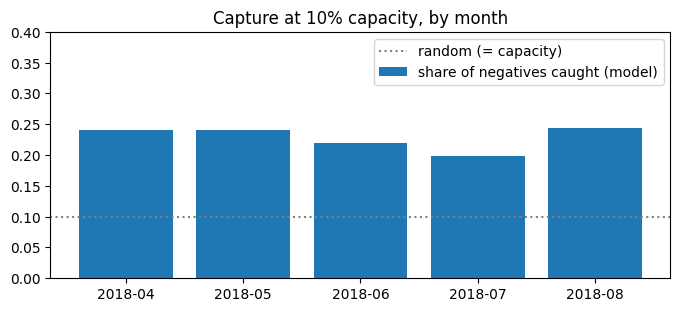

last month: 2018-08 capture 0.2432
spread of monthly capture: min 0.1979, max 0.2432, std 0.0195


,month,orders,negative_rate,capture,precision,roc_auc
0,2018-04,6726,0.1307,0.2412,0.3090,0.6691
1,2018-05,7029,0.1198,0.2399,0.2813,0.6476
2,2018-06,6139,0.1075,0.2197,0.2324,0.6405
3,2018-07,6131,0.1096,0.1979,0.2125,0.6081
4,2018-08,6646,0.1107,0.2432,0.2648,0.6179


In [9]:
monthly = pd.read_csv(OUT / "monthly.csv")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(monthly.month, monthly.capture, color="C0", label="share of negatives caught (model)")
ax.axhline(E.capacity, color="grey", linestyle=":", label="random (= capacity)")
ax.set_ylim(0, 0.4); ax.legend(loc="upper right"); ax.set_title("Capture at 10% capacity, by month")
plt.show()
print("last month:", metrics["last_month"]["month"], "capture", round(metrics["last_month"]["capture"], 4))
print(f"spread of monthly capture: min {monthly.capture.min():.4f}, max {monthly.capture.max():.4f}, std {monthly.capture.std():.4f}")
monthly

## ۶. هزینه نشت: مدل تقلبی در برابر مدل واقعی

«مدل تقلبی» همان خانواده و همان ویژگی‌ها را دارد، به‌اضافه پنج ستون وسوسه‌کننده‌ای که کنار گذاشتم:
- وضعیت نهایی
- روزهای تأخیر
- مدت تحویل
- پرچم ناهمخوانی وضعیت و تحویل
- نرخ منفی فروشنده روی همه زمان‌ها

این مدل از مسیر عادی آموزش رد می‌شود (`fit` ستون‌های بیرون از ممیزی را نمی‌پذیرد) و فقط با `allow_leaky=True` ساخته شده است.

In [10]:
cheat, real = metrics["cheat"], metrics["models"][metrics["family"]]
leak = pd.DataFrame({"real model": real, "cheat model": cheat}).T[["capture", "precision", "roc_auc", "pr_auc"]]
leak.loc["gap (cheat - real)"] = leak.loc["cheat model"] - leak.loc["real model"]
leak

,capture,precision,roc_auc,pr_auc
real model,0.2299,0.2616,0.6356,0.2283
cheat model,0.4410,0.5018,0.8050,0.4898
gap (cheat - real),0.2111,0.2402,0.1694,0.2615


مدل تقلبی تقریباً **دو برابر** نظرهای منفی را «شکار» می‌کند و AUC آن خیلی بالاتر است. همه این فاصله از اطلاعاتی می‌آید که در لحظه تأیید وجود ندارد. در عمل، روز اول تولید، این ستون‌ها خالی‌اند و مدل تقلبی چیزی بهتر از حدس نیست. این عدد نشان می‌دهد نشت داده چقدر می‌تواند فریبنده باشد.

## ۷. آیا منبع بیرونی (تعطیلات) چیزی اضافه کرد؟

مدل منتخب را یک بار بدون دو ویژگی تعطیلات آموزش می‌دهم و روی همان مجموعه ارزیابی می‌سنجم.

In [11]:
from data_factory.db import database
with database(config.database) as engine, engine.connect() as connection:
    frame, _ = em.read_features(connection, E.load.schema, config.clean.chunk_rows)
split = em.temporal_split(frame, E.cutoff, E.evaluation_end)
y = split.test["label_negative"].astype(bool)
holiday_columns = ("promised_working_days", "holidays_in_window")
without = em.fit(metrics["family"], split.train, SEED, drop=holiday_columns).predict_proba(split.test)[:, 1]
r_without = em.report(y, without, split.test["decision_at"], E.capacity)
pd.DataFrame({"with holidays": real, "without holidays": r_without}).T[["capture", "roc_auc", "pr_auc"]]

,capture,roc_auc,pr_auc
with holidays,0.2299,0.6356,0.2283
without holidays,0.2312,0.6386,0.2311


بدون دو ویژگی تعطیلات، شکار حتی کمی بالاتر است (0.2312 در برابر 0.2299)، که در حد نوسان است. **فرضیه تعطیلات رد شد:** در این داده سیگنال تعطیلات چیز معناداری اضافه نمی‌کند. دلیل احتمالی: `promised_days` (وعده تحویل) خودش اثر تقویم را جذب کرده است، چون فروشگاه موعد را با در نظر گرفتن تعطیلات اعلام می‌کند. این ویژگی‌ها را در مدل نگه داشتم، چون ضرری ندارند و مسیر داده بیرونی را در تولید زنده نگه می‌دارند. ولی در گزارش ادعای بهبود از آن‌ها نمی‌کنم.

## ۸. جابه‌جایی داده (Drift)

توزیع ویژگی‌های کلیدی را بین دوره آموزش و ارزیابی با PSI مقایسه می‌کنم. PSI زیر ۰.۱ یعنی پایدار، ۰.۱ تا ۰.۲۵ یعنی جابه‌جایی متوسط، و بالای ۰.۲۵ یعنی جابه‌جایی جدی.

In [12]:
drift = pd.read_csv(OUT / "drift.csv")
drift

,feature,psi,train_typical,test_typical
0,holidays_in_window,0.3395,1.0,0.0
1,total_freight,0.2732,16.5,18.38
2,promised_days,0.2548,24.0,21.0
3,promised_working_days,0.2388,16.0,15.0
4,main_category,0.1957,bed_bath_table,health_beauty
5,approval_hours,0.1745,0.3016666666666667,0.42277777777777775
6,seller_prior_negative_rate,0.1453,0.109375,0.13399778516057587
7,distance_km,0.0166,445.3242829353644,396.2671412625151
8,customer_state,0.0146,SP,SP
9,n_items,0.0000,1.0,1.0


بیشترین جابه‌جایی‌ها:
- **`holidays_in_window`:** آوریل تا اوت تعطیلات کمتری از نوامبر تا مارس دارد. این فصلی است.
- **`promised_days`:** فروشگاه در ۲۰۱۸ وعده‌های کوتاه‌تری داده است.
- **`total_freight`:** هزینه ارسال بالا رفته است.

با این حال شکار مدل در ماه‌های ارزیابی افت نکرد. نرخ نظر منفی پایه پایین آمد (از دوره پرمشکل فوریه و مارس به حدود ۱۱٪)، ولی ترتیب‌بندی سفارش‌ها کار می‌کند. چون تصمیم سهمیه‌ای است و آستانه احتمال ندارد، جابه‌جایی سطح کلی احتمال‌ها به آن آسیب نمی‌زند.

**اگر سامانه شش ماه در تولید بماند، اول چه خراب می‌شود؟**
- **سابقه فروشنده‌ها:** فروشنده‌های تازه سابقه ندارند و سهمشان بالا می‌رود.
- **وعده تحویل:** اگر سیاست وعده عوض شود، `promised_days` معنایش را از دست می‌دهد.

از کجا می‌فهمم:
1. PSI هفتگی همین ویژگی‌ها.
2. «نرخ اصابت تماس‌ها»: سهم سفارش‌های پیگیری‌شده‌ای که واقعاً نظر منفی داده‌اند. این عدد با چند هفته تأخیر (بعد از رسیدن نظرها) معلوم می‌شود.

اگر نرخ اصابت به نزدیک نرخ پایه (حدود ۱۱٪) برسد، مدل باید دوباره آموزش ببیند.

## ۹. خروجی عملیاتی و مسیر پیش‌بینی برای داده دیده‌نشده

خروجی سامانه، فهرست‌های روزانه آخرین ماه در `data/curated/ews/followup_list.csv` است.

نقطه ورود برای داده تازه، `data-factory ews-predict --input <folder> --output <file>` است:
1. پوشه‌ای از فایل‌های سفارش تازه با همان schema مرحله ۲ می‌گیرد.
2. همان قرارداد را اعمال می‌کند.
3. در یک تراکنش، از همان view ویژگی‌ها را می‌خواند.
4. تراکنش را rollback می‌کند.
5. فهرست رتبه‌بندی‌شده می‌دهد.

برای نمایش، یک برش زمانی (۱۵ تا ۲۰ اوت ۲۰۱۸) از فایل‌های خام Olist می‌سازم، همان کاری که ارزیاب می‌کند. این فایل‌ها را فقط نقطه ورود می‌خواند، نه مدل.

In [13]:
followup = pd.read_csv(OUT / "followup_list.csv")
print(timings["results"]["followup"])
display(followup.head(5))

raw, slice_dir = config.paths.raw / "olist", config.paths.work / "ews_demo_slice"
slice_dir.mkdir(parents=True, exist_ok=True)
orders = pd.read_csv(raw / "olist_orders_dataset.csv", dtype=str)
orders = orders[(orders.order_purchase_timestamp >= "2018-08-15") & (orders.order_purchase_timestamp < "2018-08-21")]
orders.to_csv(slice_dir / "olist_orders_dataset.csv", index=False)
for name in ("olist_order_items_dataset.csv", "olist_order_payments_dataset.csv"):
    part = pd.read_csv(raw / name, dtype=str)
    part[part.order_id.isin(orders.order_id)].to_csv(slice_dir / name, index=False)
customers = pd.read_csv(raw / "olist_customers_dataset.csv", dtype=str)
customers[customers.customer_id.isin(orders.customer_id)].to_csv(slice_dir / "olist_customers_dataset.csv", index=False)

ranked = predict_folder(config, slice_dir, config.paths.work / "ews_demo_ranked.csv")
same = ranked.merge(followup, on="order_id", suffixes=("", "_system"))
print(f"{len(ranked)} orders ranked, {int(ranked.follow_up.sum())} to follow up; "
      f"largest difference from the system's own scores: {(same.risk_score - same.risk_score_system).abs().max()}")
ranked.head(5)

{'month': '2018-08', 'orders': 6673, 'to_follow': 681}


,order_id,decision_day,risk_score,follow_up,rank_in_day
0,55881111-d8b3-7a0e-45cf-97b156ae1943,2018-08-01,0.6323,True,1
1,6dfd5e5c-5068-dadb-b8ac-93001b69677b,2018-08-01,0.6290,True,2
2,b2727344-d4f9-55cb-6182-9ed7f61b12fc,2018-08-01,0.5362,True,3
3,0f380511-57b7-ad1d-4e0b-6c5d20de6ae7,2018-08-01,0.5308,True,4
4,3e0c3cab-458e-8b3c-c8d1-d38ecb7e7775,2018-08-01,0.4983,True,5


1523 orders ranked, 157 to follow up; largest difference from the system's own scores: 9.71445146547012e-17


,order_id,decision_day,risk_score,follow_up,rank_in_day
0,947e9c6b-fd83-a069-53c4-20ef92d3da6e,2018-08-15,0.6711,True,1
1,9380c590-12c1-1f49-c549-ef8dffef1367,2018-08-15,0.6528,True,2
2,f81e71dd-7c04-4a9e-e7c1-d6e37d68d64f,2018-08-15,0.6512,True,3
3,3a4e65de-6ffd-941f-6a4e-e824d472aabb,2018-08-15,0.5292,True,4
4,ccd2795b-4fd3-3757-b039-fb15b8a12109,2018-08-15,0.5037,True,5


In [14]:
broken = config.paths.work / "ews_demo_broken"
shutil.copytree(slice_dir, broken, dirs_exist_ok=True)
pd.read_csv(broken / "olist_orders_dataset.csv", dtype=str).drop(columns=["order_estimated_delivery_date"]).to_csv(
    broken / "olist_orders_dataset.csv", index=False)
try:
    predict_folder(config, broken, config.paths.work / "never_written.csv")
except SourceSchemaChangedError as error:
    print("refused (exit code", error.exit_code.value, "):", error)

refused (exit code 32 ): olist_orders_dataset.csv: columns missing from the source: ['order_estimated_delivery_date']


## ۱۰. جمع‌بندی

- **یک فرمان**، از پایگاه داده خالی تا فهرست روزانه، زیر بودجه ۴۵ دقیقه.
- **ممیزی زمانی:** هر ستون ممیزی شده است. مدل فقط ستون‌های مجاز را می‌پذیرد و تست ضدنشت با «بازنویسی آینده» ثابت می‌کند هیچ ویژگی از آینده نمی‌خواند.
- **نتیجه مدل:** با ۱۰٪ ظرفیت، مدل 23.0٪ نظرهای منفی را شکار می‌کند، یعنی **بیش از دو برابر** انتخاب تصادفی (lift 2.26)، و کمی بیشتر از قاعده ساده (21.1٪). مدل تقلبی دو برابر این عدد را نشان می‌دهد، که همه‌اش نشت است.
- **منبع بیرونی:** فرضیه تعطیلات آزموده و رد شد.